1.	Lab 1 Overview
*	Basic operations with arrays: Using NumPy
*	Signal representation: Loading and visualizing audio
*	Spectral analysis: Computing spectrograms
*	Filtering and feature extraction: Audio feature computation

1. Basic operations with arrays: Using NumPy

In [2]:
import numpy as np
import matplotlib.pyplot as plt

a = np.array([1, 2])              # vector/"1D-array" with values 1 and 2
b = np.array([3, 4])              # same, values 3 and 4
ab1 = np.vstack((a, b))           # stacks them into a matrix
ab2 = np.array([[1, 2], [3, 4]])  # same as ab1
c = np.ones((2, 3))               # 2D-array with 2 rows and 3 columns, filled with ones.
d = np.log(ab2)                   # natural logarithm

e = [1, 2, 3, 4, 5]               # a list (not numpy)
f = list(np.arange(3, 8))         # [3, 4, 5, 6, 7]
g = np.sum(e)                     # sum of the elements in e
h = np.sum((e, f))                # sum of the elements in both e and f
i = np.sum(ab1, axis=0)           # sum per column of the matrix

m = e[0]                          # first element of e
n = e[1:3]                        # indices 2 and 3 of e
o = e[-1]                         # last element of e
p = len(e)                        # number of elements in e
q = [1, 2, [3, 4,4,6,8,9,0,], 5]  # nested lists --> length of q?

print('a: {}'.format(a))
print('b: {}'.format(b))
print('ab1:\n {}'.format(ab1))
print('ab2:\n {}'.format(ab2))
print('c:\n {}'.format(c))
print('d:\n {}'.format(d))
print('g: {}'.format(g))
print('h: {}'.format(h))
print('i: {}'.format(i))
print('m: {}, n: {}, o: {}'.format(m, n, o))
print('p: {}, len(q): {}'.format(p, len(q)))

a: [1 2]
b: [3 4]
ab1:
 [[1 2]
 [3 4]]
ab2:
 [[1 2]
 [3 4]]
c:
 [[1. 1. 1.]
 [1. 1. 1.]]
d:
 [[0.         0.69314718]
 [1.09861229 1.38629436]]
g: 15
h: 40
i: [4 6]
m: 1, n: [2, 3], o: 5
p: 5, len(q): 4


---
# (2) Sine wave
Next, we create a sine wave, which helps us get introduced to more Python concepts. Topics:

*   formula for a sine wave
*   get to know *matplotlib* for plotting graphs

Create a 1-second sinusoid with an amplitude of 3, a frequency of the note E3 (164,81 Hz) at a sample rate (fs) of 22050 Hz. Then sample the first 500 elements for the plot.

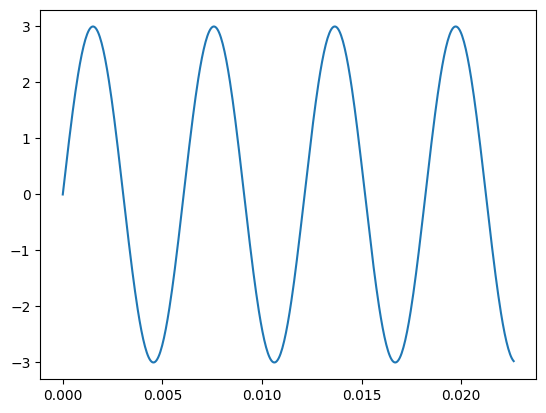

In [7]:
from matplotlib import pyplot as plt
import numpy as np
import IPython.display as ipd

A = 3
f = 164.81
fs = 22050
t = np.arange(0, 1, 1/fs)
x = A*np.sin(2*np.pi*f*t)

plt.plot(t[:500], x[:500])
plt.show()

ipd.Audio(x, rate=fs)

### Load an audio file

len: 90951 samples, sample rate: 44100
len: 90951 samples, sample rate: 44100


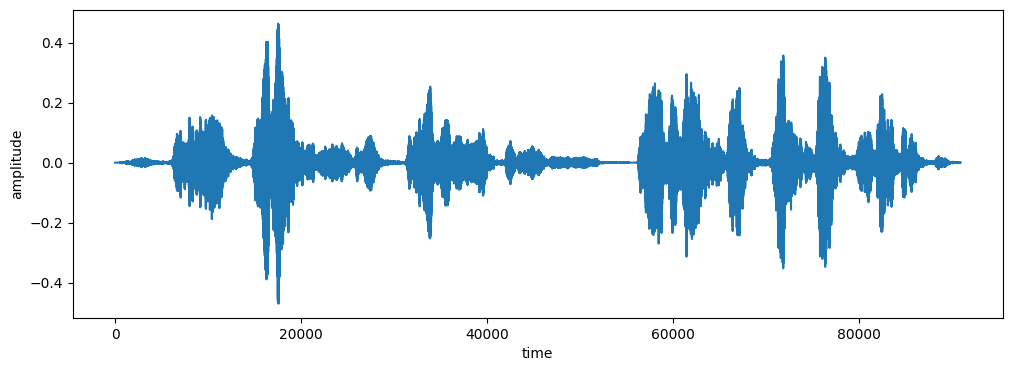

In [11]:
import soundfile as sf
import librosa

x, sf = sf.read('bird.wav')
print(f'len: {len(x)} samples, sample rate: {sf}')

x, sf = librosa.load('bird.wav', sr=None)
print(f'len: {len(x)} samples, sample rate: {sf}')

plt.figure(figsize=(12, 4))
plt.plot(x)
plt.xlabel('time')
plt.ylabel('amplitude')
plt.show()

### Let's compute the Fourier Transform using Numpy!!!

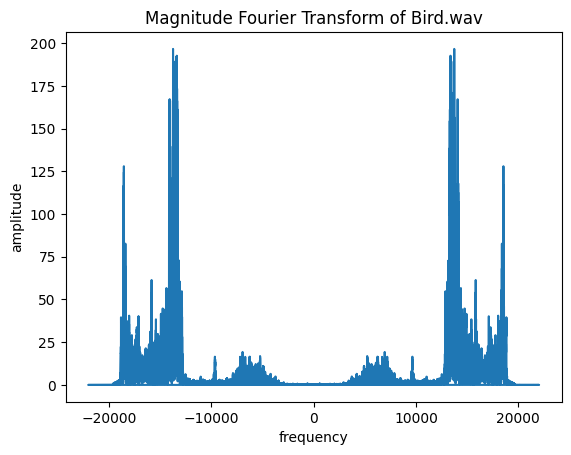

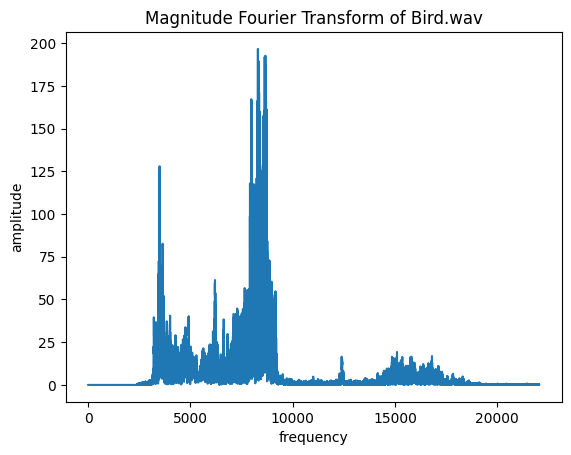

In [14]:
# USE FFT
X = np.fft.fft(x)
f = np.linspace(0, sf, len(X))
f = np.fft.fftfreq(len(X), 1/sf)
plt.plot(f, np.abs(np.fft.fftshift(X)))
plt.xlabel('frequency')
plt.ylabel('amplitude')
plt.title('Magnitude Fourier Transform of Bird.wav')
plt.show()

# USE RFFT
X = np.fft.rfft(x)
f = np.fft.rfftfreq(len(x), 1/sf)
plt.plot(f, np.abs(X))
plt.xlabel('frequency')
plt.ylabel('amplitude')
plt.title('Magnitude Fourier Transform of Bird.wav')
plt.show()

## Now let's compute the STFT

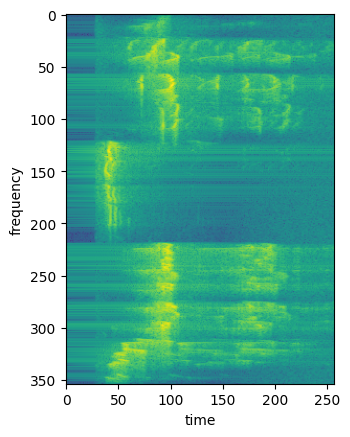

In [27]:
frame_size = 512
hop_size = 256

nframes = 1 + (len(x)-frame_size) // hop_size

frames = np.zeros((nframes, frame_size))
for i in range(nframes):
    frames[i] = x[i*hop_size:i*hop_size+frame_size]

window = np.hamming(frame_size)
window = np.expand_dims(window, axis=0)

frames = frames*window
X = np.fft.rfft(frames, axis=1)

plt.imshow(20*np.log10(np.abs(X)))
plt.xlabel('time')
plt.ylabel('frequency')
plt.show()


## REPEAT WITH DIFFERENT RESOLUTIONS

<ipython-input-40-c4166636c18a>:2: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  librosa.display.specshow(librosa.amplitude_to_db(X),


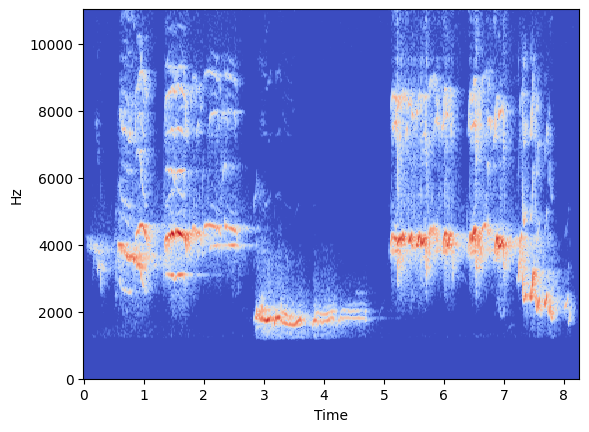

In [40]:
X = librosa.stft(x, win_length=frame_size, hop_length=hop_size)
librosa.display.specshow(librosa.amplitude_to_db(X),
                         y_axis='hz', x_axis='time')
plt.show()

# X = librosa.stft(x, win_length=frame_size//4, hop_length=hop_size//4)
# librosa.display.specshow(librosa.amplitude_to_db(X),
#                         y_axis='hz', x_axis='time')
# plt.show()

## Mel features

shape: (128, 356)


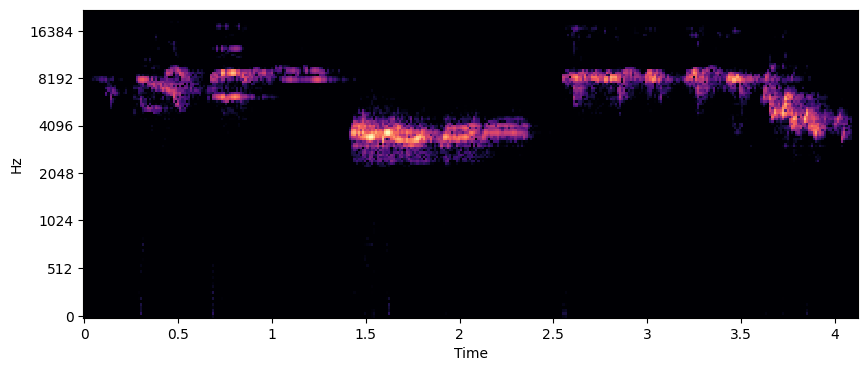

In [41]:
S = librosa.feature.melspectrogram(S=X, sr=sf, n_mels=128)
print(f'shape: {S.shape}')
plt.figure(figsize=(10, 4))
librosa.display.specshow(librosa.amplitude_to_db(np.abs(S)), x_axis='time',
                         y_axis='mel', sr=sf)

## Now let's try with music

len: 169600 samples, sample rate: 44100
shape: (84, 332)


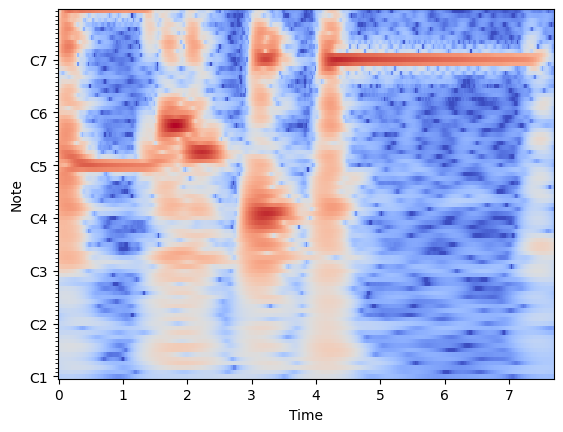

In [46]:
x, sf = librosa.load('piano.wav', sr=None)
print(f'len: {len(x)} samples, sample rate: {sf}')

C = librosa.cqt(x, sr=sf, fmin=librosa.note_to_hz('C2'), n_bins=84,   bins_per_octave=36)
print(f'shape: {C.shape}')
librosa.display.specshow(librosa.amplitude_to_db(np.abs(C)), y_axis='cqt_note', x_axis='time')
plt.show()

### Let's see MFCCs

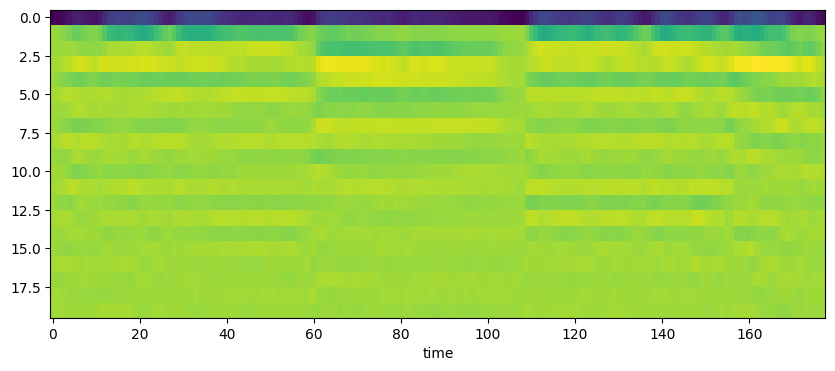

In [58]:
x_bird, sf = librosa.load('bird.wav', sr=None)
x_piano, sf = librosa.load('piano.wav', sr=None)

mfccs = librosa.feature.mfcc(y=x_bird, sr=sf, n_mfcc=20, lifter=0)
plt.figure(figsize=(10, 4))
plt.imshow(mfccs, cmap='viridis', aspect='auto')
plt.xlabel('time')
plt.show()